## BÀI 4 (TRANG 26): PHÂN LỚP DỮ LIỆU CHẤT LƯỢNG RƯỢU VANG (RED WINE QUALITY)
**Họ tên sinh viên:** Lương Thị Kim Ngân  
**MSSV:** 6451071049  
**Lớp:** CQ.64.CN.CNTT  
**Repository Github:** https://github.com/kimngan11/6451071049_Lab2  

Dữ liệu Red Wine Quality liên quan đến các mẫu rượu vang Vinho Verde đỏ từ Bồ Đào Nha. Mục tiêu là mô hình hóa chất lượng rượu (`quality`) dựa trên 11 chỉ số hóa lý đo đạc được.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049")
print("Đã import các thư viện cần thiết!")


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Đã import các thư viện cần thiết!


### Câu 3: Nhập dữ liệu và khảo sát độ tương đồng giữa các cột bằng công thức Pearson
Khảo sát độ tương quan Pearson giữa các thuộc tính hóa lý của rượu và trực quan hóa bằng biểu đồ Heatmap.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước tập dữ liệu Red Wine: (1599, 12)
Thông tin các thuộc tính:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


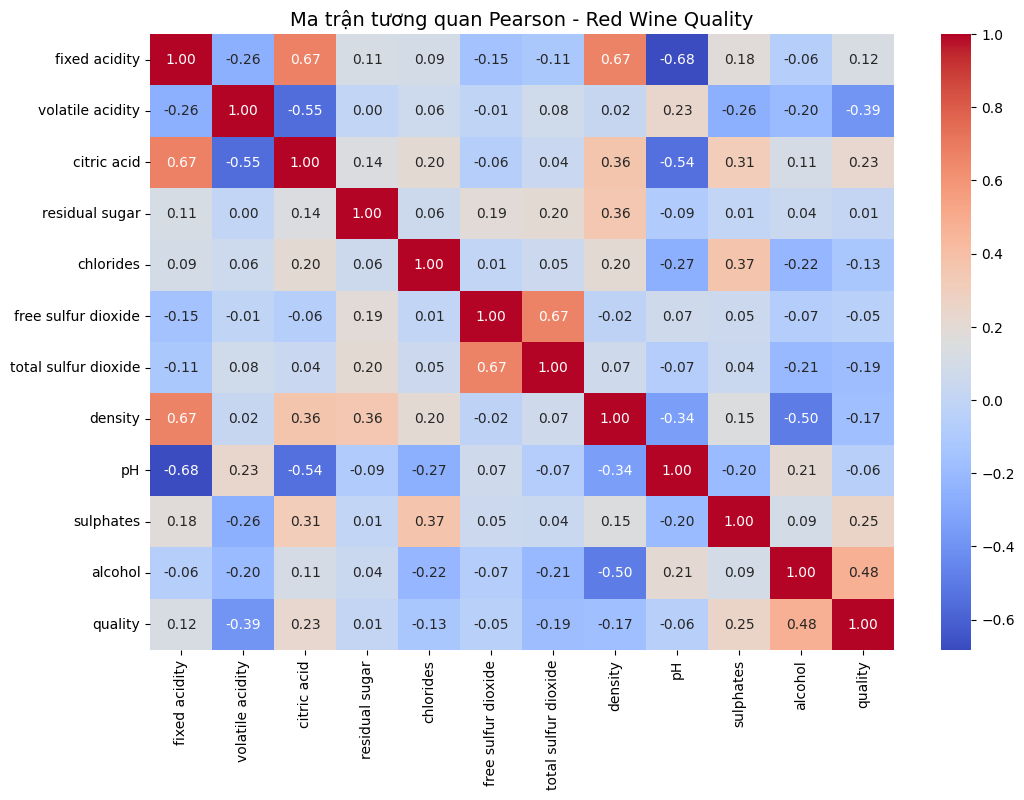

In [7]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
df = pd.read_csv('winequality-red.csv', sep=';')
print("Kích thước tập dữ liệu Red Wine:", df.shape)
print("Thông tin các thuộc tính:\n")
df.info()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Ma trận tương quan Pearson - Red Wine Quality", fontsize=14)
plt.show()

### Câu 4: Tách các cột dữ liệu thành hai phần
- `X`: Chứa 11 thuộc tính hóa lý bình thường.
- `y`: Chứa riêng thuộc tính quyết định `'quality'`.


In [8]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
X = df.drop('quality', axis=1)
y = df['quality']

print("Kích thước ma trận đặc trưng X:", X.shape)
print("Kích thước vector nhãn y:", y.shape)
print("\nPhân bố các mức chất lượng rượu (quality):")
print(y.value_counts().sort_index())


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước ma trận đặc trưng X: (1599, 11)
Kích thước vector nhãn y: (1599,)

Phân bố các mức chất lượng rượu (quality):
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
Kiểm tra các kiểu dữ liệu của các cột trong tập đặc trưng `X`.


In [9]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
cat_cols = X.select_dtypes(exclude=['int64', 'float64']).columns
print("Các thuộc tính không phải dạng số trong X:", cat_cols.tolist())
print("- Toàn bộ 11 thuộc tính hóa lý đều đã ở dạng số thực (float64).")
print("- Do đó, không cần chuyển đổi One-hot vector, dữ liệu đầu vào đã sẵn sàng cho mô hình!")


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Các thuộc tính không phải dạng số trong X: []
- Toàn bộ 11 thuộc tính hóa lý đều đã ở dạng số thực (float64).
- Do đó, không cần chuyển đổi One-hot vector, dữ liệu đầu vào đã sẵn sàng cho mô hình!


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện 70% và kiểm thử 30%
Sử dụng câu lệnh theo hướng dẫn trong tài liệu:
`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)`


In [10]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Số lượng dữ liệu huấn luyện (Train 70%):", len(X_train))
print("Số lượng dữ liệu kiểm thử (Test 30%):", len(X_test))


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Số lượng dữ liệu huấn luyện (Train 70%): 1119
Số lượng dữ liệu kiểm thử (Test 30%): 480


### Câu 7: Xây dựng cây quyết định ID3 (criterion='entropy')
Huấn luyện cây ID3, kiểm thử bằng ma trận nhầm lẫn và biểu diễn cây.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy ID3): 0.5979

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.09      0.12      0.10        17
           5       0.71      0.67      0.69       195
           6       0.61      0.62      0.62       200
           7       0.46      0.46      0.46        61
           8       0.33      0.33      0.33         6

    accuracy                           0.60       480
   macro avg       0.37      0.37      0.37       480
weighted avg       0.61      0.60      0.60       480



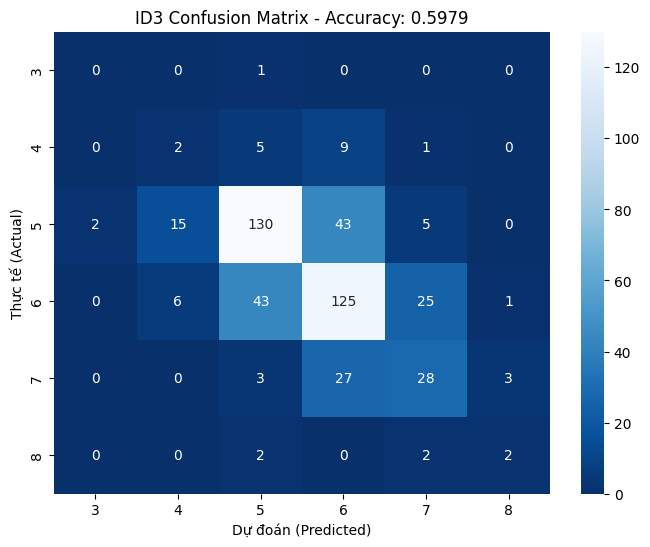

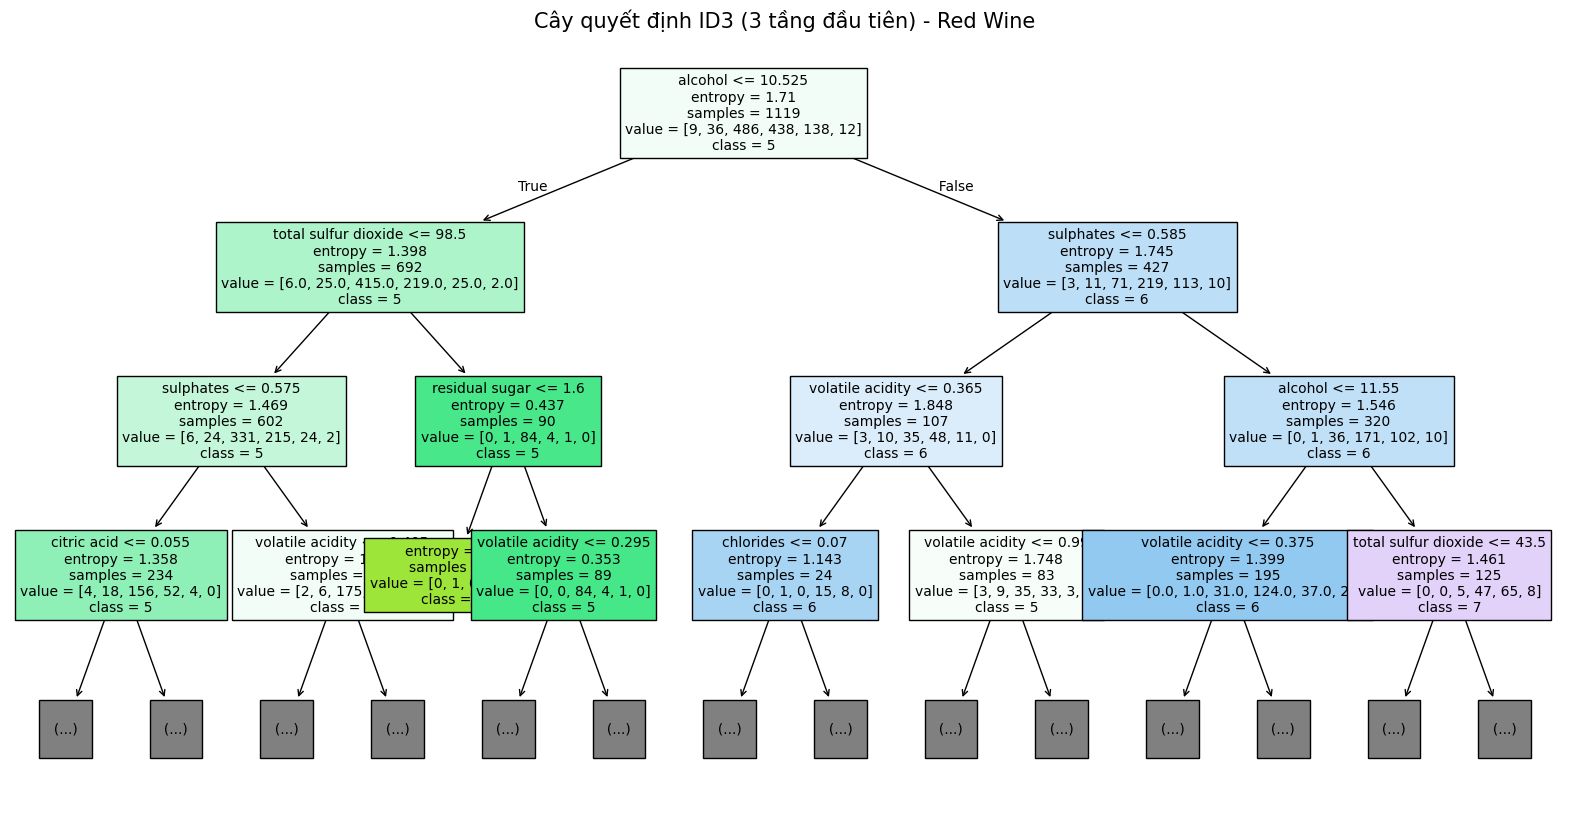

In [11]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print(f"Độ chính xác (Accuracy ID3): {id3_score:.4f}")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, id3_pred, zero_division=0))

# Ma trận nhầm lẫn
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", cmap='Blues_r',
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.title(f"ID3 Confusion Matrix - Accuracy: {id3_score:.4f}")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()

# Trực quan hóa cây quyết định mẫu (3 tầng đầu)
fig, ax = plt.subplots(figsize=(20, 10))
tree.plot_tree(clf_id3, max_depth=3, feature_names=X.columns, class_names=[str(c) for c in clf_id3.classes_], filled=True, fontsize=10)
plt.title("Cây quyết định ID3 (3 tầng đầu tiên) - Red Wine", fontsize=15)
plt.savefig('decision_tree_wine_id3.png', dpi=100, bbox_inches='tight')
plt.show()


### Câu 8: Xây dựng cây quyết định CART (criterion='gini')
Lặp lại yêu cầu 7 đối với cây CART với chỉ số phân tách Gini.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy CART): 0.5729

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.60      0.59       200
           7       0.46      0.43      0.44        61
           8       0.33      0.17      0.22         6

    accuracy                           0.57       480
   macro avg       0.35      0.32      0.33       480
weighted avg       0.57      0.57      0.57       480



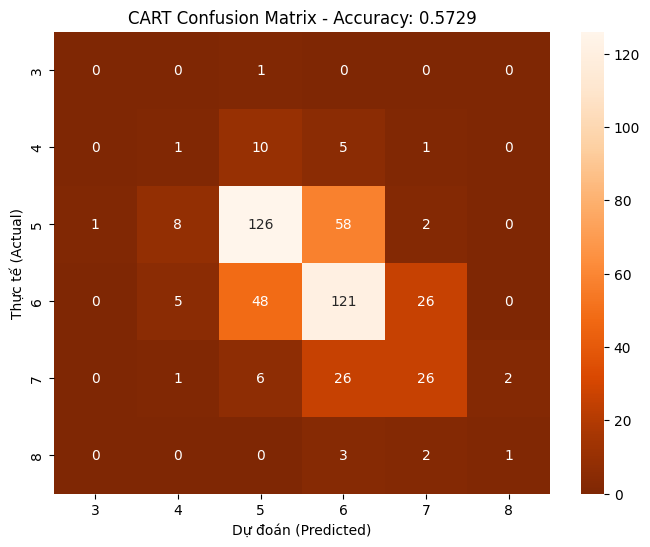

In [12]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print(f"Độ chính xác (Accuracy CART): {cart_score:.4f}")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, cart_pred, zero_division=0))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", cmap='Oranges_r',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.title(f"CART Confusion Matrix - Accuracy: {cart_score:.4f}")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()


### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes
Sử dụng thuật toán GaussianNB trên tập dữ liệu Red Wine.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy Naive Bayes): 0.5417

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



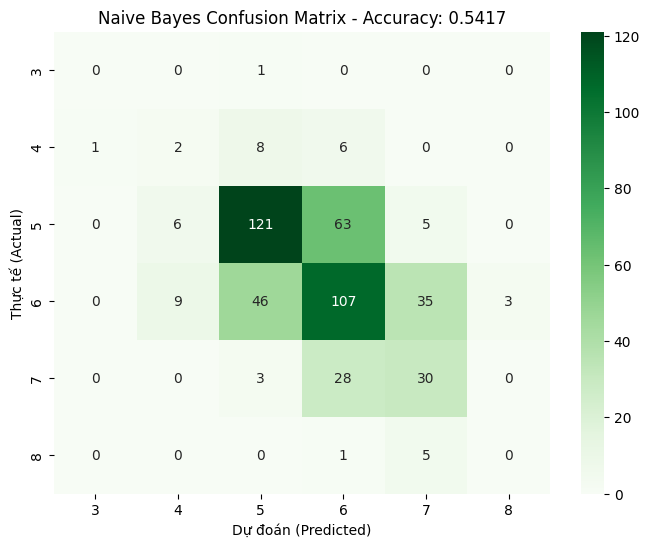

In [13]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
gnb = GaussianNB()
nb_pred = gnb.fit(X_train, y_train).predict(X_test)
nb_score = metrics.accuracy_score(y_test, nb_pred)

print(f"Độ chính xác (Accuracy Naive Bayes): {nb_score:.4f}")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, nb_pred, zero_division=0))

# Ma trận nhầm lẫn
nb_cm = metrics.confusion_matrix(y_test, nb_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(nb_cm, annot=True, fmt="d", cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.title(f"Naive Bayes Confusion Matrix - Accuracy: {nb_score:.4f}")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()


### Câu 10: So sánh kết quả của các mô hình trên dữ liệu Red Wine Quality


In [15]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
comp_wine = pd.DataFrame({
    'Mô hình': ['ID3 (Entropy)', 'CART (Gini)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [id3_score, cart_score, nb_score],
    'Macro Precision': [
        metrics.precision_score(y_test, id3_pred, average='macro', zero_division=0),
        metrics.precision_score(y_test, cart_pred, average='macro', zero_division=0),
        metrics.precision_score(y_test, nb_pred, average='macro', zero_division=0)
    ],
    'Macro Recall': [
        metrics.recall_score(y_test, id3_pred, average='macro', zero_division=0),
        metrics.recall_score(y_test, cart_pred, average='macro', zero_division=0),
        metrics.recall_score(y_test, nb_pred, average='macro', zero_division=0)
    ],
    'Macro F1-score': [
        metrics.f1_score(y_test, id3_pred, average='macro', zero_division=0),
        metrics.f1_score(y_test, cart_pred, average='macro', zero_division=0),
        metrics.f1_score(y_test, nb_pred, average='macro', zero_division=0)
    ]
})
print("BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP DỮ LIỆU RED WINE QUALITY:")
print(comp_wine.to_string(index=False))


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP DỮ LIỆU RED WINE QUALITY:
                 Mô hình  Accuracy  Macro Precision  Macro Recall  Macro F1-score
           ID3 (Entropy)  0.597917         0.366429      0.366944        0.366196
             CART (Gini)  0.572917         0.347317      0.317146        0.327368
Naïve Bayes (GaussianNB)  0.541667         0.285929      0.294161        0.289046
